# CNN + BiLTSM

## Cargar librerías

In [1]:
import os, random, numpy as np
from pathlib import Path
from typing import Dict, Any

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder

import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, LearningRateMonitor, Callback
from pytorch_lightning.loggers import CSVLogger
from torchmetrics.classification import MulticlassAccuracy, MulticlassPrecision, MulticlassRecall, MulticlassF1Score

## CONFIG

In [2]:
DATA_ROOT    = Path(r"C:\Users\RICHI\Documents\Tesis\Data\GTZAN\GTZAN_LogMel2D")   # <-- AJUSTA
SPLITS       = {"train": "train", "val": "val", "test": "test"}

IMG_SIZE     = (224, 224)
BATCH_SIZE   = 32
NUM_WORKERS  = 0 if os.name == "nt" else 4
MAX_EPOCHS   = 100
LR           = 2e-4
WD           = 1e-4
DROPOUT      = 0.3
LSTM_HIDDEN  = 256
LSTM_LAYERS  = 2
SEED         = 42

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.set_float32_matmul_precision("high")

## DATAMODULE

In [3]:
class SpectrogramDataModule(pl.LightningDataModule):
    def __init__(self, data_root: Path, splits: dict, batch_size: int, num_workers: int):
        super().__init__()
        self.data_root   = Path(data_root)
        self.splits      = splits
        self.batch_size  = batch_size
        self.num_workers = num_workers
        self.tx_train = transforms.Compose([
            transforms.Grayscale(num_output_channels=1),
            transforms.Resize(IMG_SIZE, antialias=True),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.5], std=[0.5]),
        ])
        self.tx_eval = transforms.Compose([
            transforms.Grayscale(num_output_channels=1),
            transforms.Resize(IMG_SIZE, antialias=True),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.5], std=[0.5]),
        ])
    def setup(self, stage=None):
        root = self.data_root
        self.ds_train = ImageFolder(root / self.splits["train"], transform=self.tx_train)
        self.ds_val   = ImageFolder(root / self.splits["val"],   transform=self.tx_eval)
        self.ds_test  = ImageFolder(root / self.splits["test"],  transform=self.tx_eval)
        self.num_classes = len(self.ds_train.classes)
    def train_dataloader(self):
        return DataLoader(self.ds_train, batch_size=self.batch_size, shuffle=True,
                          num_workers=self.num_workers, pin_memory=True)
    def val_dataloader(self):
        return DataLoader(self.ds_val, batch_size=self.batch_size, shuffle=False,
                          num_workers=self.num_workers, pin_memory=True)
    def test_dataloader(self):
        return DataLoader(self.ds_test, batch_size=self.batch_size, shuffle=False,
                          num_workers=self.num_workers, pin_memory=True)

## MODELO

In [4]:
class CNNEncoder(nn.Module):
    def __init__(self, in_ch=1, dropout=0.3):
        super().__init__()
        c1,c2,c3,c4 = 32,64,128,256
        self.block1 = nn.Sequential(
            nn.Conv2d(in_ch,c1,3,padding=1), nn.BatchNorm2d(c1), nn.ReLU(inplace=True),
            nn.Conv2d(c1,c1,3,padding=1),    nn.BatchNorm2d(c1), nn.ReLU(inplace=True),
            nn.MaxPool2d((2,2)), nn.Dropout(dropout)
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(c1,c2,3,padding=1), nn.BatchNorm2d(c2), nn.ReLU(inplace=True),
            nn.Conv2d(c2,c2,3,padding=1), nn.BatchNorm2d(c2), nn.ReLU(inplace=True),
            nn.MaxPool2d((2,2)), nn.Dropout(dropout)
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(c2,c3,3,padding=1), nn.BatchNorm2d(c3), nn.ReLU(inplace=True),
            nn.Conv2d(c3,c3,3,padding=1), nn.BatchNorm2d(c3), nn.ReLU(inplace=True),
            nn.MaxPool2d((2,2)), nn.Dropout(dropout)
        )
        self.block4 = nn.Sequential(
            nn.Conv2d(c3,c4,3,padding=1), nn.BatchNorm2d(c4), nn.ReLU(inplace=True),
            nn.Conv2d(c4,c4,3,padding=1), nn.BatchNorm2d(c4), nn.ReLU(inplace=True),
            nn.MaxPool2d((2,1)), nn.Dropout(dropout)   # pool solo en frecuencia
        )
    def forward(self, x):
        x = self.block1(x); x = self.block2(x); x = self.block3(x); x = self.block4(x)
        return x  # [B,256,F',T']

class CNNBiLSTMClassifier(pl.LightningModule):
    def __init__(self, num_classes, lr=2e-4, wd=1e-4, dropout=0.3, lstm_hidden=256, lstm_layers=2):
        super().__init__()
        self.save_hyperparameters()
        self.enc = CNNEncoder(1, dropout)
        self.freq_pool = nn.AdaptiveAvgPool2d((1, None))           # [B,256,1,T']
        self.lstm = nn.LSTM(256, lstm_hidden, num_layers=lstm_layers,
                            batch_first=True, bidirectional=True, dropout=dropout)
        self.head = nn.Sequential(
            nn.Linear(2*lstm_hidden, 2*lstm_hidden), nn.ReLU(inplace=True),
            nn.Dropout(dropout), nn.Linear(2*lstm_hidden, num_classes)
        )
        self.crit = nn.CrossEntropyLoss(label_smoothing=0.1)
        # métricas
        self.train_acc  = MulticlassAccuracy(num_classes=num_classes, average='macro')
        self.val_acc    = MulticlassAccuracy(num_classes=num_classes, average='macro')
        self.test_acc   = MulticlassAccuracy(num_classes=num_classes, average='macro')
        self.train_prec = MulticlassPrecision(num_classes=num_classes, average='macro')
        self.val_prec   = MulticlassPrecision(num_classes=num_classes, average='macro')
        self.test_prec  = MulticlassPrecision(num_classes=num_classes, average='macro')
        self.train_rec  = MulticlassRecall(num_classes=num_classes, average='macro')
        self.val_rec    = MulticlassRecall(num_classes=num_classes, average='macro')
        self.test_rec   = MulticlassRecall(num_classes=num_classes, average='macro')
        self.train_f1   = MulticlassF1Score(num_classes=num_classes, average='macro')
        self.val_f1     = MulticlassF1Score(num_classes=num_classes, average='macro')
        self.test_f1    = MulticlassF1Score(num_classes=num_classes, average='macro')

    def forward(self, x):
        f = self.enc(x)                       # [B,256,F',T']
        f = self.freq_pool(f).squeeze(2)      # [B,256,T']
        f = f.permute(0,2,1)                  # [B,T',256]
        out,_ = self.lstm(f)                  # [B,T',2*h]
        h = out.mean(dim=1)                   # [B,2*h]
        return self.head(h)                   # [B,C]

    def _shared_step(self, batch, stage):
        x,y = batch
        logits = self(x)
        loss = self.crit(logits, y)
        preds = logits.argmax(1)
        if stage=='train':
            self.train_acc.update(preds,y); self.train_prec.update(preds,y)
            self.train_rec.update(preds,y); self.train_f1.update(preds,y)
            self.log('train/loss', loss, on_step=False, on_epoch=True, prog_bar=False)
        elif stage=='val':
            self.val_acc.update(preds,y); self.val_prec.update(preds,y)
            self.val_rec.update(preds,y); self.val_f1.update(preds,y)
            self.log('val/loss', loss, on_step=False, on_epoch=True, prog_bar=True)
        else:
            self.test_acc.update(preds,y); self.test_prec.update(preds,y)
            self.test_rec.update(preds,y); self.test_f1.update(preds,y)
            self.log('test/loss', loss, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def training_step(self, batch, batch_idx):   return self._shared_step(batch,'train')
    def validation_step(self, batch, batch_idx): return self._shared_step(batch,'val')
    def test_step(self, batch, batch_idx):       return self._shared_step(batch,'test')

    def on_train_epoch_end(self):
        acc=self.train_acc.compute(); self.train_acc.reset()
        pr =self.train_prec.compute(); self.train_prec.reset()
        rc =self.train_rec.compute();  self.train_rec.reset()
        f1 =self.train_f1.compute();   self.train_f1.reset()
        self.log_dict({'train/acc':acc,'train/prec':pr,'train/rec':rc,'train/f1':f1}, prog_bar=True)

    def on_validation_epoch_end(self):
        acc=self.val_acc.compute(); self.val_acc.reset()
        pr =self.val_prec.compute(); self.val_prec.reset()
        rc =self.val_rec.compute();  self.val_rec.reset()
        f1 =self.val_f1.compute();   self.val_f1.reset()
        self.log_dict({'val/acc':acc,'val/prec':pr,'val/rec':rc,'val/f1':f1}, prog_bar=True)

    def on_test_epoch_end(self):
        acc=self.test_acc.compute(); self.test_acc.reset()
        pr =self.test_prec.compute(); self.test_prec.reset()
        rc =self.test_rec.compute();  self.test_rec.reset()
        f1 =self.test_f1.compute();   self.test_f1.reset()
        self.log_dict({'test/acc':acc,'test/prec':pr,'test/rec':rc,'test/f1':f1}, prog_bar=True)

    def configure_optimizers(self):
        opt = torch.optim.AdamW(self.parameters(), lr=LR, weight_decay=WD)
        def sch_lambda(epoch):
            warmup=5
            if epoch < warmup: return (epoch+1)/warmup
            t = (epoch-warmup)/max(1,(MAX_EPOCHS-warmup))
            return 0.5*(1+np.cos(np.pi*t))
        sch = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda=sch_lambda)
        return {"optimizer": opt, "lr_scheduler": sch}

## Callback

In [5]:
class EpochMetricsPrinter(Callback):
    """Imprime métricas de train/val al cierre de cada época."""
    KEYS = [
        'train/loss','train/acc','train/prec','train/rec','train/f1',
        'val/loss','val/acc','val/prec','val/rec','val/f1'
    ]
    def _fmt(self, x: Any):
        try:
            return f"{float(x):.4f}"
        except Exception:
            return str(x)
    def on_validation_epoch_end(self, trainer: pl.Trainer, pl_module: pl.LightningModule):
        m: Dict[str, Any] = trainer.callback_metrics
        e = trainer.current_epoch
        vals = {k:self._fmt(m.get(k, float('nan'))) for k in self.KEYS}
        print(
            f"[Epoch {e:03d}] "
            f"TRAIN: loss={vals['train/loss']}  acc={vals['train/acc']}  "
            f"prec={vals['train/prec']}  rec={vals['train/rec']}  f1={vals['train/f1']}  |  "
            f"VAL: loss={vals['val/loss']}  acc={vals['val/acc']}  "
            f"prec={vals['val/prec']}  rec={vals['val/rec']}  f1={vals['val/f1']}"
        )

## Entrenamiento

In [7]:
def run_training():
    dm = SpectrogramDataModule(DATA_ROOT, SPLITS, BATCH_SIZE, NUM_WORKERS)
    dm.setup()
    print("Clases:", dm.ds_train.classes)
    print(f"train={len(dm.ds_train)} | val={len(dm.ds_val)} | test={len(dm.ds_test)}")

    model = CNNBiLSTMClassifier(num_classes=dm.num_classes, dropout=DROPOUT,
                                lstm_hidden=LSTM_HIDDEN, lstm_layers=LSTM_LAYERS)

    ckpt  = ModelCheckpoint(monitor='val/acc', mode='max', save_top_k=1, save_last=True,
                            filename='cnnlstm-{epoch:02d}-{val_acc:.3f}')
    early = EarlyStopping(monitor='val/acc', mode='max', patience=10)
    lrmon = LearningRateMonitor(logging_interval='epoch')
    logger = CSVLogger("logs", name="cnnlstm")
    printer = EpochMetricsPrinter()

    trainer = pl.Trainer(
        max_epochs=MAX_EPOCHS,
        accelerator='auto', devices='auto',
        precision='16-mixed',
        callbacks=[ckpt, early, lrmon, printer],   # <--- imprime por época
        logger=[logger],
        log_every_n_steps=25
    )

    trainer.fit(model, datamodule=dm)
    print("Best ckpt:", ckpt.best_model_path or "<none>", "| best:", ckpt.best_model_score)
    trainer.test(model=None, datamodule=dm, ckpt_path=('best' if ckpt.best_model_path else None))
    print("CSV logs:", logger.log_dir)

if __name__ == "__main__":
    run_training()

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores


Clases: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
train=29323 | val=1196 | test=600


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

   | Name       | Type                | Params | Mode 
------------------------------------------------------------
0  | enc        | CNNEncoder          | 1.2 M  | train
1  | freq_pool  | AdaptiveAvgPool2d   | 0      | train
2  | lstm       | LSTM                | 2.6 M  | train
3  | head       | Sequential          | 267 K  | train
4  | crit       | CrossEntropyLoss    | 0      | train
5  | train_acc  | MulticlassAccuracy  | 0      | train
6  | val_acc    | MulticlassAccuracy  | 0      | train
7  | test_acc   | MulticlassAccuracy  | 0      | train
8  | train_prec | MulticlassPrecision | 0      | train
9  | val_prec   | MulticlassPrecision | 0      | train
10 | test_prec  | MulticlassPrecision | 0      | train
11 | train_rec  | MulticlassRecall    | 0      | train
12 | val_rec    | MulticlassRecall    | 0      | train
13 | test_rec   | MulticlassRecall    | 0      | train
14 | train_f1   | MulticlassF1Score   | 0      | train
15 | val_f1     

Epoch 53: 100%|██████████| 917/917 [02:54<00:00,  5.25it/s, v_num=3, val/loss=1.270, val/acc=0.754, val/prec=0.774, val/rec=0.754, val/f1=0.754, train/acc=0.996, train/prec=0.996, train/rec=0.996, train/f1=0.996]
Best ckpt: logs\cnnlstm\version_3\checkpoints\cnnlstm-epoch=43-val_acc=0.000.ckpt | best: tensor(0.7708, device='cuda:0')


Restoring states from the checkpoint path at logs\cnnlstm\version_3\checkpoints\cnnlstm-epoch=43-val_acc=0.000.ckpt
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Loaded model weights from the checkpoint at logs\cnnlstm\version_3\checkpoints\cnnlstm-epoch=43-val_acc=0.000.ckpt
c:\Users\RICHI\anaconda3\envs\TesisRichiFix2\Lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:433: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


Testing DataLoader 0: 100%|██████████| 19/19 [00:07<00:00,  2.63it/s]
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test/acc            0.7783333659172058
         test/f1            0.7766127586364746
        test/loss           1.1862963438034058
        test/prec           0.7912749648094177
        test/rec            0.7783333659172058
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
CSV logs: logs\cnnlstm\version_3


In [8]:
# === Utils: versión reciente, curvas loss (desde CSVLogger), preds.csv, reporte y CM ===
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Ajusta si cambiaste el nombre del experimento en CSVLogger
LOG_ROOT = Path(r"C:\Users\RICHI\Documents\Tesis\TesisRichi\codigo\logs\cnnlstm")

def latest_version_dir(log_root: Path) -> Path:
    if not log_root.exists():
        raise FileNotFoundError(f"No existe {log_root}")
    versions = sorted([p for p in log_root.glob("version_*") if p.is_dir()],
                      key=lambda p: int(re.sub(r".*_(\d+)$", r"\1", p.name)))
    return versions[-1] if versions else log_root

def pick_ckpt(version_dir: Path) -> Path:
    ckpt_dir = version_dir / "checkpoints"
    if not ckpt_dir.exists():
        raise FileNotFoundError(f"No existe {ckpt_dir}")
    # Preferir last.ckpt; si no, el más reciente por mtime.
    last = ckpt_dir / "last.ckpt"
    if last.exists(): 
        return last
    ckpts = sorted(ckpt_dir.glob("*.ckpt"), key=lambda p: p.stat().st_mtime)
    if not ckpts:
        raise FileNotFoundError(f"Sin .ckpt en {ckpt_dir}")
    return ckpts[-1]

def plot_losses_from_metrics(version_dir: Path, save_as: Path | None = None, smooth: int | None = 3):
    metrics_path = version_dir / "metrics.csv"
    if not metrics_path.exists():
        raise FileNotFoundError(f"No existe {metrics_path}")
    df = pd.read_csv(metrics_path)
    # normaliza nombres: train/loss -> train_loss; val.loss -> val_loss; quita espacios
    df.columns = [re.sub(r"[\/\.\:\s]+", "_", str(c).strip()) for c in df.columns]
    # colapsa duplicadas (evita TypeError en to_numeric)
    if df.columns.duplicated().any():
        df = df.T.groupby(level=0).last().T
    # eje x: epoch > step > índice
    epoch_col = "epoch" if "epoch" in df.columns else ("step" if "step" in df.columns else None)
    if epoch_col is None:
        df["epoch"] = np.arange(len(df)); epoch_col = "epoch"
    # convierte a numérico (excepto x)
    num_cols = [c for c in df.columns if c != epoch_col]
    df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")
    # último registro por época/paso
    sdf = df.groupby(epoch_col, as_index=False).agg({c: "last" for c in num_cols})
    # detectar columnas de pérdida
    loss_cols = [c for c in sdf.columns if c != epoch_col and "loss" in c.lower() and not c.lower().endswith("_step") and sdf[c].notna().any()]
    train_like = [c for c in loss_cols if any(k in c.lower() for k in ["train","tr","training"])]
    val_like   = [c for c in loss_cols if any(k in c.lower() for k in ["val","valid","validation"])]
    to_plot = (sorted(train_like) + sorted(val_like)) or sorted(loss_cols)
    if not to_plot:
        raise RuntimeError(f"No hay columnas de pérdida para graficar. Columnas: {list(sdf.columns)}")
    def smooth_series(s, w):
        if not w or w <= 1 or len(s) < w: return s
        return pd.Series(s).rolling(window=w, min_periods=1).mean()
    plt.figure()
    for c in to_plot:
        y = smooth_series(sdf[c], smooth)
        plt.plot(sdf[epoch_col], y, label=c)
    plt.xlabel(epoch_col); plt.ylabel("loss"); plt.title("Curvas de pérdida (train/val)")
    plt.legend()
    if save_as:
        save_as.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_as, bbox_inches="tight")
    plt.show()

@torch.no_grad()
def export_preds_and_metrics(ckpt_path: Path, dm, split: str, out_dir: Path):
    """
    split: 'val' o 'test'. Requiere tu clase CNNBiLSTMClassifier definida en el notebook.
    Genera preds.csv y muestra classification_report + matriz de confusión.
    """
    # Reimport local class from current notebook scope
    # CNNBiLSTMClassifier ya está definido en tu notebook
    model = CNNBiLSTMClassifier.load_from_checkpoint(str(ckpt_path))
    model.eval().cuda() if torch.cuda.is_available() else model.eval()

    # obtener dataloader según split
    if split == "val":
        loader = dm.val_dataloader()
    elif split == "test":
        loader = dm.test_dataloader()
    else:
        raise ValueError("split debe ser 'val' o 'test'")

    y_true, y_pred = [], []
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    for batch in loader:
        x, y = batch
        x = x.to(device); y = y.to(device)
        logits = model(x)
        preds = logits.argmax(1)
        y_true.append(y.detach().cpu().numpy())
        y_pred.append(preds.detach().cpu().numpy())

    y_true = np.concatenate(y_true); y_pred = np.concatenate(y_pred)
    out_dir.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"y_true": y_true, "y_pred": y_pred}).to_csv(out_dir / "preds.csv", index=False)

    print(classification_report(y_true, y_pred, digits=4))
    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm).plot(values_format="d")
    plt.title(f"Matriz de confusión ({split})")
    plt.show()


Versión analizada: C:\Users\RICHI\Documents\Tesis\TesisRichi\codigo\logs\cnnlstm\version_3


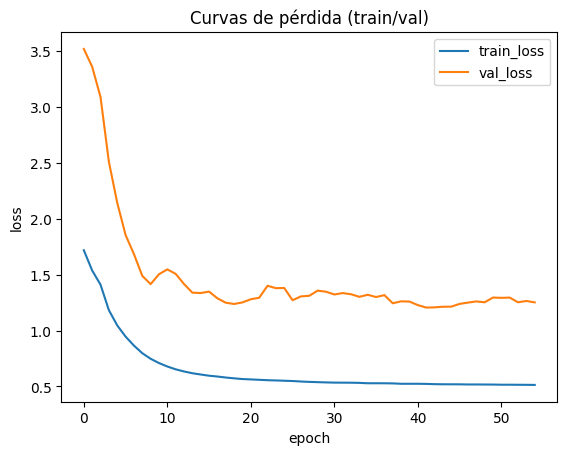

Checkpoint usado: last.ckpt
              precision    recall  f1-score   support

           0     0.8974    0.5833    0.7071        60
           1     0.8571    1.0000    0.9231        60
           2     0.7692    0.5000    0.6061        60
           3     0.7612    0.8500    0.8031        60
           4     0.9000    0.7500    0.8182        60
           5     0.7273    0.8000    0.7619        60
           6     0.7619    0.8000    0.7805        60
           7     0.7500    0.6000    0.6667        60
           8     0.8281    0.8833    0.8548        60
           9     0.4894    0.7667    0.5974        60

    accuracy                         0.7533       600
   macro avg     0.7742    0.7533    0.7519       600
weighted avg     0.7742    0.7533    0.7519       600



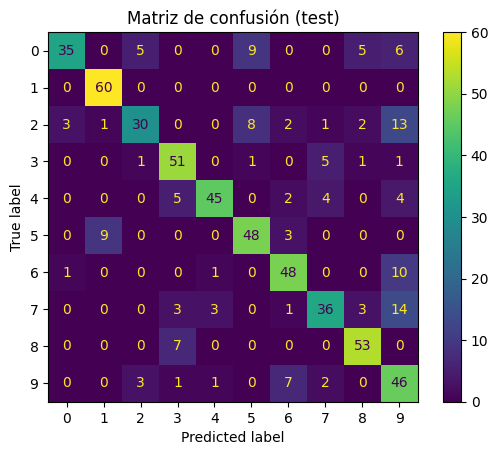

In [9]:
# === Ejecutar ANÁLISIS tras el entrenamiento ===
# Recrea el DataModule con los mismos hiperparámetros usados en run_training()
dm = SpectrogramDataModule(DATA_ROOT, SPLITS, BATCH_SIZE, NUM_WORKERS)
dm.setup()

version_dir = latest_version_dir(LOG_ROOT)
print("Versión analizada:", version_dir)

# Curvas de pérdida desde metrics.csv del CSVLogger
plot_losses_from_metrics(version_dir, save_as=version_dir / "loss_curves.png", smooth=3)

# Escoge checkpoint (last.ckpt o el más reciente) y exporta métricas + preds.csv
ckpt_path = pick_ckpt(version_dir)
print("Checkpoint usado:", ckpt_path.name)

# Usa 'test' si quieres métricas finales del conjunto de prueba; 'val' para validación
export_preds_and_metrics(ckpt_path, dm, split="test", out_dir=version_dir)
